# Mutual Information and Information Theory in Modern ML

**What you'll learn**

- Mutual information as *shared uncertainty* — three equivalent definitions verified in code,
  and why MI captures every kind of dependence while correlation captures one.
- Why MI estimates are dangerously easy to inflate (binning bias), and the permutation-null
  guard every practitioner should use.
- MI for feature screening: what it catches that correlation misses, what *both* miss
  (interactions/synergy), and an mRMR mini-implementation for redundancy-aware selection.
- Decision trees as MI maximizers: information gain from scratch, matched against sklearn.
- The **data processing inequality** — post-processing can only lose information — and its two
  business faces: coarsened features and noisy labels that cap achievable performance.
- NMI vs AMI vs ARI for comparing segmentations, and the chance-inflation trap.
- The LLM-era toolkit, built small enough to fully understand: a character n-gram language
  model with **perplexity** computed from cross-entropy, **temperature** as an entropy dial,
  the **reward-vs-KL frontier** that underlies RLHF-style fine-tuning, and **distillation**
  (why soft targets carry more information than hard labels — demonstrated).

**Why it matters in interviews**

- "MI vs correlation", "how do trees choose splits", and "what is perplexity" are bread-and-butter
  senior applied-scientist questions.
- Temperature, KL penalties, and distillation are the working vocabulary of any team touching
  LLMs — being able to *demonstrate* them on paper-sized examples reads as real fluency.
- The data processing inequality is the cleanest way to reason about label quality, feature
  pipelines, and why "more modeling" can't fix upstream information loss.

Prerequisite: [../01_statistical_foundations/06_entropy_crossentropy_kl.ipynb](../01_statistical_foundations/06_entropy_crossentropy_kl.ipynb)
(entropy, cross-entropy, KL). Related: [05_explainability_shap](05_explainability_shap.ipynb)
(model-based importance), [../08_product_analytics/04_segmentation_clustering.ipynb](../08_product_analytics/04_segmentation_clustering.ipynb) (cluster stability).

In [1]:
import re
import pathlib

import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.feature_selection import mutual_info_classif, mutual_info_regression
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (adjusted_mutual_info_score, adjusted_rand_score, log_loss,
                             normalized_mutual_info_score, roc_auc_score)
from sklearn.tree import DecisionTreeClassifier

rng = np.random.default_rng(42)
plt.rcParams.update({"figure.figsize": (9, 4.5), "axes.grid": True, "grid.alpha": 0.3})
LN2 = np.log(2)

def H_bits(p):
    p = np.asarray(p, float); p = p[p > 0]
    return float(-(p * np.log2(p)).sum())

## 1. Mutual information: three definitions, one number

$$I(X;Y) \;=\; H(X) + H(Y) - H(X,Y) \;=\; H(Y) - H(Y|X) \;=\; \mathrm{KL}\big(p(x,y)\,\|\,p(x)p(y)\big)$$

Read them as: *shared uncertainty*, *how much knowing X reduces surprise about Y*, and *how far
the joint is from independence*. It is symmetric, non-negative, zero **iff** X and Y are
independent, and measured in bits. Verify all three on a discrete business joint —
subscription plan vs churn:

In [2]:
plans = ["basic", "pro", "enterprise"]
# p(plan, churned)
joint = np.array([
    #  stay    churn
    [0.42,    0.13],    # basic: churny
    [0.28,    0.05],    # pro
    [0.11,    0.01],    # enterprise: sticky
])
joint /= joint.sum()
p_plan, p_churn = joint.sum(1), joint.sum(0)

I_hh = H_bits(p_plan) + H_bits(p_churn) - H_bits(joint.ravel())
H_churn_given_plan = sum(p_plan[i] * H_bits(joint[i] / p_plan[i]) for i in range(3))
I_cond = H_bits(p_churn) - H_churn_given_plan
indep = np.outer(p_plan, p_churn)
I_kl = (joint * np.log2(joint / indep)).sum()

print(f"H(plan)+H(churn)-H(joint) = {I_hh:.5f} bits")
print(f"H(churn) - H(churn|plan)  = {I_cond:.5f} bits")
print(f"KL(joint || independence) = {I_kl:.5f} bits   ← all three identical")
print(f"\nFor scale: H(churn) = {H_bits(p_churn):.3f} bits; plan explains "
      f"{I_kl / H_bits(p_churn):.1%} of the churn uncertainty.")

H(plan)+H(churn)-H(joint) = 0.01540 bits
H(churn) - H(churn|plan)  = 0.01540 bits
KL(joint || independence) = 0.01540 bits   ← all three identical

For scale: H(churn) = 0.701 bits; plan explains 2.2% of the churn uncertainty.


That last line is the **uncertainty coefficient** (Theil's U) — MI normalized by the target's
entropy — a far more honest "how much does this segment explain?" number than eyeballing rate
differences.

## 2. Correlation sees one direction of dependence; MI sees them all

Pearson correlation measures *linear* association. MI measures *any* departure from
independence. The classic gallery — each panel shows a real, strong relationship; correlation
notices only the first:

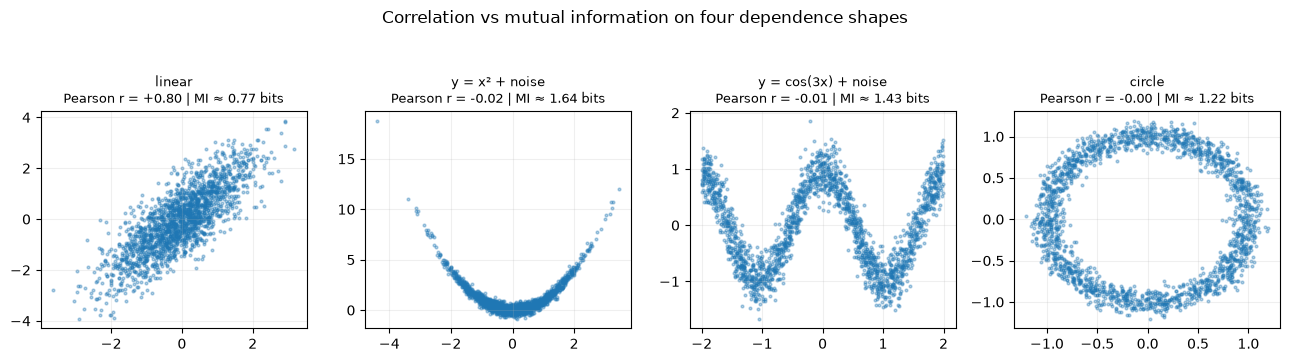

In [3]:
n = 2000
x_lin = rng.normal(0, 1, n);  y_lin = x_lin + rng.normal(0, 0.75, n)
x_par = rng.normal(0, 1, n);  y_par = x_par**2 + rng.normal(0, 0.3, n)
x_cos = rng.uniform(-2, 2, n); y_cos = np.cos(3 * x_cos) + rng.normal(0, 0.25, n)
ang = rng.uniform(0, 2 * np.pi, n)
x_cir = np.cos(ang) + rng.normal(0, 0.08, n); y_cir = np.sin(ang) + rng.normal(0, 0.08, n)

panels = [("linear", x_lin, y_lin), ("y = x² + noise", x_par, y_par),
          ("y = cos(3x) + noise", x_cos, y_cos), ("circle", x_cir, y_cir)]
fig, axes = plt.subplots(1, 4, figsize=(13, 3.4))
for ax, (name, x_, y_) in zip(axes, panels):
    r = np.corrcoef(x_, y_)[0, 1]
    mi = mutual_info_regression(x_[:, None], y_, random_state=0)[0] / LN2
    ax.scatter(x_, y_, s=4, alpha=0.35)
    ax.set_title(f"{name}\nPearson r = {r:+.2f} | MI ≈ {mi:.2f} bits", fontsize=9)
    ax.grid(alpha=0.2)
plt.suptitle("Correlation vs mutual information on four dependence shapes", y=1.05)
plt.tight_layout(); plt.show()

The parabola, the cosine, and the circle are *strongly* dependent — knowing x tells you a lot
about y — with correlations near zero. (Continuous MI here is estimated with sklearn's
k-nearest-neighbor estimator, in the Kraskov–Stögbauer–Grassberger family; we convert its nats
to bits.) The reverse direction also matters: MI has no sign — it tells you dependence
*exists*, not its direction or shape. Correlation's sign and magnitude remain the right summary
when the relationship *is* roughly monotone.

## 3. Estimating MI is easy to get wrong

The plug-in estimator (bin both variables, apply the formula) is **biased upward**: with many
bins and modest n, pure noise produces impressive-looking MI. This is the entropy small-sample
bias from the [foundations notebook](../01_statistical_foundations/06_entropy_crossentropy_kl.ipynb),
working against you in the worst direction.

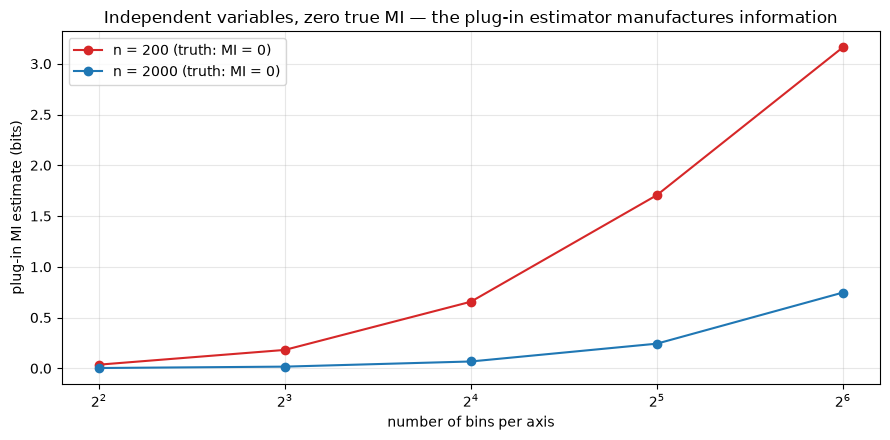

In [4]:
def plugin_mi_bits(x, y, bins):
    c, _, _ = np.histogram2d(x, y, bins=bins)
    pxy = c / c.sum()
    px, py = pxy.sum(1, keepdims=True), pxy.sum(0, keepdims=True)
    mask = pxy > 0
    return (pxy[mask] * np.log2(pxy[mask] / (px @ py)[mask])).sum()

bin_grid = [4, 8, 16, 32, 64]
fig, ax = plt.subplots()
for n_s, color in [(200, "tab:red"), (2000, "tab:blue")]:
    est = np.zeros((60, len(bin_grid)))
    for r_i in range(60):
        x_ind = rng.normal(0, 1, n_s)
        y_ind = rng.normal(0, 1, n_s)          # independent: true MI = 0
        est[r_i] = [plugin_mi_bits(x_ind, y_ind, b) for b in bin_grid]
    ax.plot(bin_grid, est.mean(0), "o-", color=color, label=f"n = {n_s} (truth: MI = 0)")
ax.set_xscale("log", base=2)
ax.set_xlabel("number of bins per axis"); ax.set_ylabel("plug-in MI estimate (bits)")
ax.set_title("Independent variables, zero true MI — the plug-in estimator manufactures information")
ax.legend(); plt.tight_layout(); plt.show()

At n = 200 with a 64×64 grid, *independent* noise scores ≈ several bits of "information". The
bias scales like (bins²)/n. Defenses, in order of practicality:

1. **Permutation null** — shuffle y, recompute MI many times, and compare your estimate to that
   null distribution. Costs a loop; saves careers.
2. Fewer bins / adaptive bins, or the KNN (KSG) estimator sklearn uses.
3. Report MI *minus* the permutation-null mean (a bias-corrected effect size).

In [5]:
def mi_with_permutation_null(x, y, bins=16, n_perm=200, rng=None):
    obs = plugin_mi_bits(x, y, bins)
    null = np.array([plugin_mi_bits(x, rng.permutation(y), bins) for _ in range(n_perm)])
    return obs, null.mean(), np.quantile(null, 0.95), (null >= obs).mean()

x_dep = rng.normal(0, 1, 500)
y_dep = np.cos(2.5 * x_dep) + rng.normal(0, 0.6, 500)     # real (nonlinear) signal
x_no = rng.normal(0, 1, 500)
y_no = rng.normal(0, 1, 500)                              # nothing

for name, x_, y_ in [("cos signal", x_dep, y_dep), ("independent", x_no, y_no)]:
    obs, nmean, n95, pval = mi_with_permutation_null(x_, y_, rng=rng)
    verdict = "REAL dependence" if obs > n95 else "consistent with noise"
    print(f"{name:12s}: MI = {obs:.3f} bits | null mean {nmean:.3f}, null 95th {n95:.3f} "
          f"| p ≈ {pval:.3f} → {verdict}")

cos signal  : MI = 0.852 bits | null mean 0.296, null 95th 0.334 | p ≈ 0.000 → REAL dependence
independent : MI = 0.268 bits | null mean 0.299, null 95th 0.332 | p ≈ 0.920 → consistent with noise


Same estimator, same bins — the permutation null tells the signal from the artifact. This
pattern (estimate → shuffle → compare) is the single most useful habit in dependence mining.

## 4. Feature screening: what MI catches, and what nothing univariate catches

Screening features against a target with MI beats correlation when relationships are
non-monotone. But **both** are univariate: a feature whose effect only exists in interaction
with another feature is invisible to each alone. Build all three cases and watch:

In [6]:
n_f = 4000
X = rng.normal(0, 1, (n_f, 6))
y_scr = (1.5 * X[:, 0]                       # linear signal      → both see it
         + 2.0 * np.cos(2 * X[:, 1])         # symmetric nonlinear → only MI sees it
         + 2.5 * np.sign(X[:, 2] * X[:, 3])  # pure interaction    → NEITHER sees it marginally
         + rng.normal(0, 1.0, n_f))          # x4, x5 are pure noise

mi_scr = mutual_info_regression(X, y_scr, random_state=0) / LN2
rows = []
for j in range(6):
    rows.append((f"x{j}", abs(np.corrcoef(X[:, j], y_scr)[0, 1]), mi_scr[j]))
print(f"{'feature':8s} {'|corr|':>8s} {'MI (bits)':>10s}   role")
roles = ["linear", "cos (symmetric)", "interaction ½", "interaction ½", "noise", "noise"]
for (f, c, m), role in zip(rows, roles):
    print(f"{f:8s} {c:8.3f} {m:10.3f}   {role}")

inter = X[:, 2] * X[:, 3]
mi_inter = mutual_info_regression(inter[:, None], y_scr, random_state=0)[0] / LN2
print(f"\nengineered x2*x3: MI = {mi_inter:.3f} bits ← the pair carries real information, "
      "visible only jointly (synergy)")

feature    |corr|  MI (bits)   role
x0          0.436      0.217   linear
x1          0.012      0.147   cos (symmetric)
x2          0.012      0.001   interaction ½
x3          0.025      0.000   interaction ½
x4          0.012      0.000   noise
x5          0.009      0.009   noise

engineered x2*x3: MI = 0.548 bits ← the pair carries real information, visible only jointly (synergy)


Readings:

- **x0 (linear)**: both metrics flag it. **x1 (cosine)**: correlation ~0, MI clearly > noise —
  the screening win for MI.
- **x2, x3 (interaction)**: MI ≈ noise level for each alone, yet their *product* carries
  ~half a bit. Univariate screening — MI included — cannot see synergy. This is why screening
  is a *pre-filter*, not a decision: model-based importance on a learner that can represent
  interactions ([05_explainability_shap](05_explainability_shap.ipynb)) is the complement.
- The mirror problem is **redundancy**: two near-copies of a good feature both screen high.
  mRMR (max-relevance, min-redundancy) fixes the ranking with one extra term:

In [7]:
X7 = np.column_stack([X, X[:, 0] + rng.normal(0, 0.15, n_f)])   # x6 = near-copy of x0
names7 = [f"x{j}" for j in range(6)] + ["x6≈x0"]
rel = mutual_info_regression(X7, y_scr, random_state=0) / LN2   # relevance to y

selected, remaining = [], list(range(7))
for _ in range(4):
    best, best_score = None, -np.inf
    for j in remaining:
        red = (np.mean([mutual_info_regression(X7[:, [j]], X7[:, s], random_state=0)[0] / LN2
                        for s in selected]) if selected else 0.0)
        score = rel[j] - red
        if score > best_score:
            best, best_score = j, score
    selected.append(best); remaining.remove(best)
    print(f"pick {len(selected)}: {names7[best]:6s} (relevance {rel[best]:.3f}, "
          f"score after redundancy penalty {best_score:+.3f})")

dup_red = mutual_info_regression(X7[:, [6]], X7[:, 0], random_state=0)[0] / LN2
print(f"\nthe near-duplicate x6≈x0: relevance {rel[6]:.3f} bits (looks great!) but "
      f"MI(x6; x0) = {dup_red:.2f} bits")
print(f"→ its mRMR score is {rel[6] - dup_red:+.2f}: highly relevant, entirely redundant, never picked.")
print("Caveat: once real signal is exhausted (picks 3-4 have scores ≈ 0), mRMR starts ranking")
print("noise — a screening list should be CUT where scores hit the permutation-null floor.")

pick 1: x0     (relevance 0.217, score after redundancy penalty +0.217)
pick 2: x1     (relevance 0.147, score after redundancy penalty +0.144)


pick 3: x5     (relevance 0.009, score after redundancy penalty +0.009)


pick 4: x2     (relevance 0.001, score after redundancy penalty +0.001)

the near-duplicate x6≈x0: relevance 0.210 bits (looks great!) but MI(x6; x0) = 2.78 bits
→ its mRMR score is -2.57: highly relevant, entirely redundant, never picked.
Caveat: once real signal is exhausted (picks 3-4 have scores ≈ 0), mRMR starts ranking
noise — a screening list should be CUT where scores hit the permutation-null floor.


## 5. Decision trees are mutual-information maximizers

A split on threshold t converts a feature into a binary variable S = 1{x > t}; the
**information gain** of the split is exactly I(S; y) = H(y) − H(y|S). "Train a tree with the
entropy criterion" means "greedily pick the split with maximal MI with the target." From scratch:

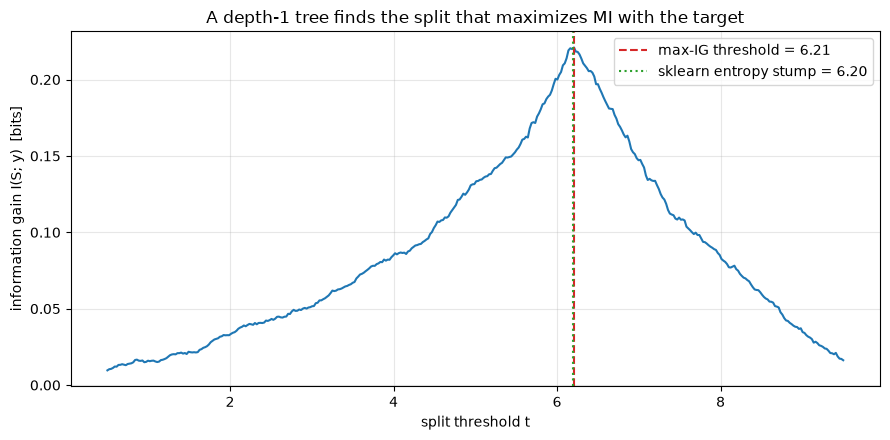

gini stump threshold: 6.20  (gini ≈ a quadratic approximation of entropy — they almost always agree)


In [8]:
n_t = 3000
x_t = rng.uniform(0, 10, n_t)
p_true = np.where(x_t > 6.2, 0.82, 0.25)         # regime change at 6.2
y_t = (rng.random(n_t) < p_true).astype(int)

def split_information_gain(x, y, t):
    left, right = y[x <= t], y[x > t]
    H = lambda arr: H_bits(np.bincount(arr, minlength=2) / len(arr)) if len(arr) else 0.0
    w = len(left) / len(y)
    return H(y) - (w * H(left) + (1 - w) * H(right))

ts = np.linspace(0.5, 9.5, 400)
gains = np.array([split_information_gain(x_t, y_t, t) for t in ts])

stump = DecisionTreeClassifier(criterion="entropy", max_depth=1, random_state=0).fit(x_t[:, None], y_t)
stump_gini = DecisionTreeClassifier(criterion="gini", max_depth=1, random_state=0).fit(x_t[:, None], y_t)

fig, ax = plt.subplots()
ax.plot(ts, gains)
ax.axvline(ts[np.argmax(gains)], color="tab:red", ls="--",
           label=f"max-IG threshold = {ts[np.argmax(gains)]:.2f}")
ax.axvline(stump.tree_.threshold[0], color="tab:green", ls=":",
           label=f"sklearn entropy stump = {stump.tree_.threshold[0]:.2f}")
ax.set_xlabel("split threshold t"); ax.set_ylabel("information gain I(S; y)  [bits]")
ax.set_title("A depth-1 tree finds the split that maximizes MI with the target")
ax.legend(); plt.tight_layout(); plt.show()
print(f"gini stump threshold: {stump_gini.tree_.threshold[0]:.2f}  "
      "(gini ≈ a quadratic approximation of entropy — they almost always agree)")

And the tree inherits MI's blindness, with a sharper twist than most people expect. XOR is
*representable* at depth 2 (split on x₀ at 0, then on x₁ at 0). But **greedy training can't
find it**: every candidate root split has IG ≈ 0, so the root cut is noise-driven, and the tree
needs several wasted levels before conditioned regions with real gain appear:

In [9]:
x_xor = rng.normal(0, 1, (4000, 2))
y_xor = (np.sign(x_xor[:, 0] * x_xor[:, 1]) > 0).astype(int)
for d in [1, 2, 3, 4, 6]:
    acc = DecisionTreeClassifier(criterion="entropy", max_depth=d, random_state=0)\
        .fit(x_xor[:2000], y_xor[:2000]).score(x_xor[2000:], y_xor[2000:])
    print(f"XOR data, tree depth {d}: holdout accuracy {acc:.3f}"
          + ("   ← representable, yet still coin-flip: greedy IG has no gradient" if d == 2 else ""))

XOR data, tree depth 1: holdout accuracy 0.490
XOR data, tree depth 2: holdout accuracy 0.497   ← representable, yet still coin-flip: greedy IG has no gradient
XOR data, tree depth 3: holdout accuracy 0.541
XOR data, tree depth 4: holdout accuracy 0.891
XOR data, tree depth 6: holdout accuracy 1.000


**Representable ≠ greedily learnable.** Depth 2 can express XOR; the greedy learner needs
depth ~4 to stumble across the information-gain plateau (randomized ensembles help for exactly
this reason — many arbitrary first cuts). The screening lesson of section 4 and the tree lesson
here are the same lesson: *marginal* information measures are blind to pure interactions.

## 6. The data processing inequality: you can only lose information downstream

If X → Y → Z is a processing chain (Z computed from Y alone), then **I(X; Z) ≤ I(X; Y)**.
No transformation, model, or cleverness applied to Y can create information about X that Y
didn't already carry. Two working-life versions:

### 6a. Coarsening features destroys information (measurably)

In [10]:
x_d = rng.normal(0, 1, 6000)
y_d = x_d + rng.normal(0, 0.5, 6000)                  # Y: noisy measurement of X
mi_xy = mutual_info_regression(y_d[:, None], x_d, random_state=0)[0] / LN2
print(f"I(X; Y)  = {mi_xy:.3f} bits (the ceiling)")
for k in [2, 4, 8, 32]:
    z = np.digitize(y_d, np.quantile(y_d, np.linspace(0, 1, k + 1)[1:-1]))
    mi_xz = mutual_info_classif(x_d[:, None], z, random_state=0)[0] / LN2
    print(f"I(X; {k:>2}-bin coarsened Y) = {mi_xz:.3f} bits")

I(X; Y)  = 1.150 bits (the ceiling)
I(X;  2-bin coarsened Y) = 0.529 bits
I(X;  4-bin coarsened Y) = 0.883 bits


I(X;  8-bin coarsened Y) = 1.037 bits


I(X; 32-bin coarsened Y) = 1.101 bits


Binning a continuous feature into 2 buckets throws away most of its information about anything
upstream; 8+ quantile bins retain nearly all of it. That's the principled answer to "does
bucketing this feature hurt?" — measure the MI drop.

### 6b. Noisy labels: what the information cap destroys — and what survives

Flip each training label with probability ε. The proxy's information about the truth collapses
fast. But *where* the damage lands is subtle, and worth measuring rather than asserting:

In [11]:
n_lab = 12_000
X_lab = rng.normal(0, 1, (n_lab, 4))
logit = X_lab @ np.array([1.2, -0.8, 0.6, 0.4])
t_true = (rng.random(n_lab) < 1 / (1 + np.exp(-logit))).astype(int)   # true label
X_tr, X_te = X_lab[:6000], X_lab[6000:]
t_tr, t_te = t_true[:6000], t_true[6000:]

print(f"{'flip ε':>7s} {'I(proxy;truth) bits':>20s} {'AUC (n=6000)':>13s} "
      f"{'logloss vs truth':>17s} {'AUC (n=250)':>12s}")
for eps in [0.0, 0.1, 0.2, 0.3, 0.4]:
    proxy = np.where(rng.random(6000) < eps, 1 - t_tr, t_tr)          # corrupted training labels
    joint_lab = np.histogram2d(t_tr, proxy, bins=2)[0] / 6000
    mi_lab = (H_bits(joint_lab.sum(1)) + H_bits(joint_lab.sum(0)) - H_bits(joint_lab.ravel()))
    big = LogisticRegression().fit(X_tr, proxy).predict_proba(X_te)[:, 1]
    small = LogisticRegression().fit(X_tr[:250], proxy[:250]).predict_proba(X_te)[:, 1]
    print(f"{eps:7.1f} {mi_lab:20.3f} {roc_auc_score(t_te, big):13.3f} "
          f"{log_loss(t_te, big):17.3f} {roc_auc_score(t_te, small):12.3f}")

 flip ε  I(proxy;truth) bits  AUC (n=6000)  logloss vs truth  AUC (n=250)


    0.0                1.000         0.824             0.514        0.813


    0.1                0.538         0.824             0.524        0.805


    0.2                0.265         0.824             0.558        0.767
    0.3                0.107         0.823             0.597        0.770
    0.4                0.028         0.823             0.649        0.621


Three different fates for three different quantities:

- **Ranking survives at scale.** Symmetric flips leave P(proxy=1|x) a *monotone* function of
  the true P(t=1|x) — the ordering is still identifiable, so with 6,000 rows the AUC against
  the truth barely moves. Information loss is not uniform across questions.
- **Sample efficiency is destroyed.** At n = 250, AUC falls with ε (0.81 → 0.62): each noisy label
  carries fewer bits (0.03 bits at ε = 0.4 vs 1 bit clean), so you pay the information debt in
  data volume — roughly 30× more labels for the same signal at ε = 0.4.
- **Calibration is destroyed and unrecoverable in place.** The learned probabilities compress
  toward the noise floor (log loss against the truth climbs) — and you cannot recalibrate your
  way out without *clean* labels to calibrate against.

The DPI is the cap on the whole chain truth → proxy → model: at ε = 0.4 the labels retain
0.03 bits/example about *which individuals* are positives, and nothing downstream can add to
it. And this was the *gentle* noise: when flips are asymmetric or correlated with features
(annotator bias on a subpopulation), the monotone link breaks and **ranking degrades too** —
with no downstream fix. Measured moral: **label-quality budgets buy sample efficiency,
calibration, and (under structured noise) correctness itself** — the information-theoretic case
for data-centric ML, and the formal cousin of the selective-labels problem in
[04_imbalanced_fraud](04_imbalanced_fraud.ipynb).

## 7. Comparing clusterings: NMI, AMI, ARI

MI also scores agreement between two *labelings* (e.g., this month's customer segments vs last
month's — see [../08_product_analytics/04_segmentation_clustering.ipynb](../08_product_analytics/04_segmentation_clustering.ipynb)).
Normalized MI (NMI) rescales to [0, 1] — but raw NMI is **inflated by chance** when there are
many clusters. Adjusted MI (AMI) subtracts the chance level:

In [12]:
labels_true = rng.integers(0, 5, 200)                   # 200 customers, 5 real segments
perm = rng.permutation(5)
labels_renamed = perm[labels_true]                      # same clustering, new names
labels_random = rng.integers(0, 60, 200)                # unrelated, but MANY clusters

for name, lab in [("identical (renamed)", labels_renamed), ("random with 60 clusters", labels_random)]:
    print(f"{name:24s}: NMI = {normalized_mutual_info_score(labels_true, lab):.3f} | "
          f"AMI = {adjusted_mutual_info_score(labels_true, lab):.3f} | "
          f"ARI = {adjusted_rand_score(labels_true, lab):.3f}")
print("→ raw NMI hands PURELY RANDOM fine-grained labels a quarter of the maximum score;")
print("  chance-adjusted AMI and ARI correctly report zero.")
print("  Rule: chance-adjusted metrics (AMI, ARI) whenever cluster counts differ or are large.")

identical (renamed)     : NMI = 1.000 | AMI = 1.000 | ARI = 1.000
random with 60 clusters : NMI = 0.245 | AMI = 0.016 | ARI = 0.004
→ raw NMI hands PURELY RANDOM fine-grained labels a quarter of the maximum score;
  chance-adjusted AMI and ARI correctly report zero.
  Rule: chance-adjusted metrics (AMI, ARI) whenever cluster counts differ or are large.


## 8. The LLM era, at paper scale

Every concept in modern language modeling headlines — perplexity, temperature, KL-regularized
fine-tuning, distillation — is entropy/KL machinery. Build them small enough to see through.

### 8a. A character language model and perplexity

A language model is a next-symbol distribution; training minimizes cross-entropy — exactly the
"wasted bits" objective of the [foundations notebook](../01_statistical_foundations/06_entropy_crossentropy_kl.ipynb).
**Perplexity = 2^(cross-entropy in bits)**: the *effective branching factor* the model still
faces per symbol. Corpus: this repo's own README and style guide.

In [13]:
text = (pathlib.Path("../README.md").read_text() + " " + pathlib.Path("../STYLE.md").read_text())
text = re.sub(r"[^a-z .,]", " ", text.lower())
text = re.sub(r"\s+", " ", text).strip()
V = sorted(set(text))
split = int(0.85 * len(text))
train, test = text[:split], text[split:]
print(f"corpus: {len(text):,} chars | vocab {len(V)} symbols | train {len(train):,} / test {len(test):,}")

def ngram_counts(corpus, order):
    ctx_counts, pair_counts = {}, {}
    for i in range(order - 1, len(corpus)):
        ctx, ch = corpus[i - order + 1:i], corpus[i]
        ctx_counts[ctx] = ctx_counts.get(ctx, 0) + 1
        pair_counts[(ctx, ch)] = pair_counts.get((ctx, ch), 0) + 1
    return ctx_counts, pair_counts

def cross_entropy_bits(corpus, ctx_counts, pair_counts, order, alpha=0.2, vocab_size=None):
    vocab_size = vocab_size or len(V)
    total = 0.0; m = 0
    for i in range(order - 1, len(corpus)):
        ctx, ch = corpus[i - order + 1:i], corpus[i]
        num = pair_counts.get((ctx, ch), 0) + alpha
        den = ctx_counts.get(ctx, 0) + alpha * vocab_size
        total += -np.log2(num / den); m += 1
    return total / m

models = {}
for order, name in [(1, "unigram"), (2, "bigram"), (3, "trigram")]:
    cc, pc = ngram_counts(train, order)
    models[order] = (cc, pc)
    ce = cross_entropy_bits(test, cc, pc, order)
    print(f"{name:8s}: test cross-entropy {ce:.3f} bits/char → perplexity {2**ce:6.2f} "
          f"(uniform would be {len(V)})")

corpus: 18,800 chars | vocab 29 symbols | train 15,980 / test 2,820
unigram : test cross-entropy 4.262 bits/char → perplexity  19.19 (uniform would be 29)
bigram  : test cross-entropy 3.694 bits/char → perplexity  12.94 (uniform would be 29)
trigram : test cross-entropy 3.342 bits/char → perplexity  10.14 (uniform would be 29)


Reading: with no model, every character is a 29-way surprise. Each order of context cuts the
effective branching factor — that *is* language modeling. GPT-class models are this exact
objective with a vastly better conditional distribution: modern LLMs reach < 1 bit/character
on English, i.e. per-character perplexity below 2. Two footnotes worth repeating in interviews:
perplexities are only comparable **on the same tokenization and corpus** (per-token vs per-char
perplexity differ mechanically), and "LLMs are compressors" is *literal* — a model with
cross-entropy H can drive an arithmetic coder that stores text at H bits/char.

### 8b. Temperature is an entropy dial

Sampling with temperature T replaces p by p^{1/T} (renormalized). T → 0 collapses to argmax
(entropy → 0); T → ∞ flattens to uniform (entropy → log₂ V). It reshapes the *distribution*;
"creativity" is just where you sit on the entropy curve.

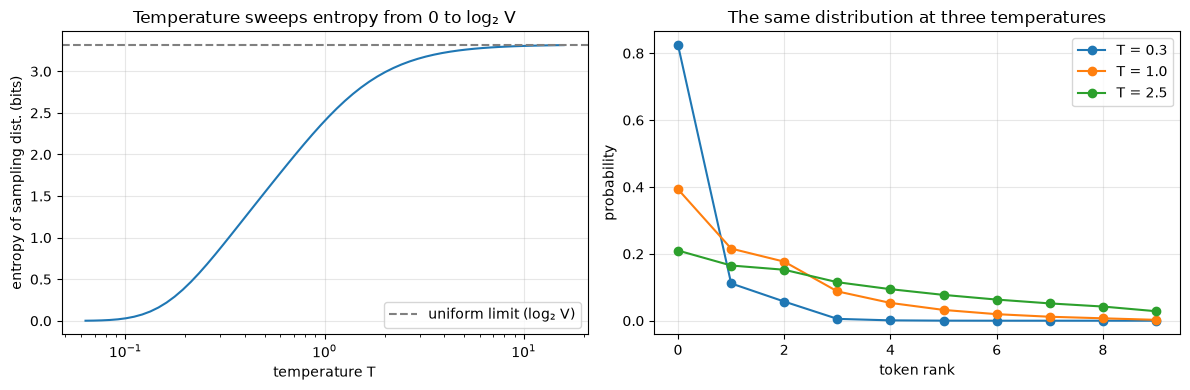

In [14]:
logits = np.array([3.0, 2.4, 2.2, 1.5, 1.0, 0.5, 0.0, -0.5, -1.0, -2.0])
def soften(p_base, T):
    q = p_base ** (1 / T)
    return q / q.sum()
p_base = np.exp(logits) / np.exp(logits).sum()

Ts = np.logspace(-1.2, 1.2, 60)
ent = [H_bits(soften(p_base, T)) for T in Ts]
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].semilogx(Ts, ent)
axes[0].axhline(np.log2(len(p_base)), color="gray", ls="--", label="uniform limit (log₂ V)")
axes[0].set_xlabel("temperature T"); axes[0].set_ylabel("entropy of sampling dist. (bits)")
axes[0].set_title("Temperature sweeps entropy from 0 to log₂ V"); axes[0].legend()
for T, c in [(0.3, "tab:blue"), (1.0, "tab:orange"), (2.5, "tab:green")]:
    axes[1].plot(soften(p_base, T), "o-", color=c, label=f"T = {T}")
axes[1].set_xlabel("token rank"); axes[1].set_ylabel("probability")
axes[1].set_title("The same distribution at three temperatures"); axes[1].legend()
plt.tight_layout(); plt.show()

In [15]:
def generate(order, n_chars, T, seed_ctx, rng):
    cc, pc = models[order]
    out = seed_ctx
    for _ in range(n_chars):
        ctx = out[-(order - 1):] if order > 1 else ""
        probs = np.array([pc.get((ctx, ch), 0) + 0.2 for ch in V], float)
        probs /= probs.sum()
        probs = soften(probs, T)
        out += V[rng.choice(len(V), p=probs)]
    return out[len(seed_ctx):]

gen_rng = np.random.default_rng(7)
for T in [0.35, 1.0, 2.5]:
    print(f"T = {T:<4}: …{generate(3, 110, T, 'th', gen_rng)!r}")

T = 0.35: …'e se sampling detration and stion men se stion cover prom the se compling and se th the prestion a bration men'
T = 1.0 : …'es w.quand pron bachurectiverving.dx,ams tionted acts postation ander tqwmx, adcas per expnqock wor encendis s'
T = 2.5 : …'sbnpobrntreqvwb qenwigio.ibrtfgmddfk.snf.ta,..xeetpcjwhq.stsoj,msaglrwadtpszyvtioessqlfi,vmiorguxiaszbrtwb.zac'


Even a trigram model shows the whole story: low temperature loops through the corpus's most
common patterns (repetitive but word-like), T = 1 samples the model faithfully, high
temperature approaches keyboard-mashing. The knob trades **coherence against diversity** by
moving entropy — nothing more mystical than that.

### 8c. Fine-tuning with a KL leash: the reward–drift frontier

RLHF-style fine-tuning maximizes a reward while penalizing KL divergence from the base model:
max_q E_q[r] − (1/β)·KL(q‖p). The optimal policy has a closed form — the **exponential tilt**
q_β(x) ∝ p(x)·e^{β·r(x)} (the same math as maximum entropy in the foundations notebook).
Sweeping β traces the fundamental trade-off curve:

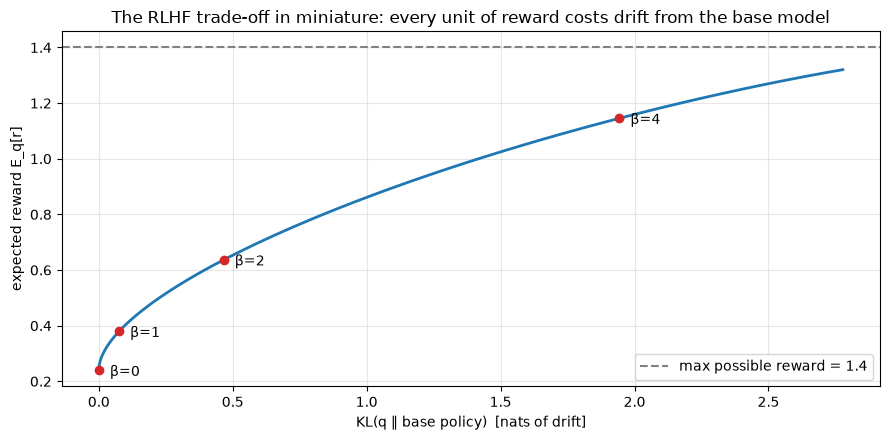

β=0: reward 0.24, KL 0 (the base model)   |   β=6: reward 1.32, KL 2.78 nats (nearly argmax-r)


In [16]:
p_base_pol = 1 / np.arange(1, 13) ** 1.1
p_base_pol /= p_base_pol.sum()                       # Zipf-ish base policy over 12 actions
reward = np.array([0.1, 0.2, 0.0, 0.4, 0.1, 0.9, 0.2, 0.1, 1.4, 0.0, 0.3, 1.1])
# note: the highest rewards sit on LOW-probability actions — the interesting case

betas = np.linspace(0, 6, 100)
ers, kls = [], []
for b in betas:
    q = p_base_pol * np.exp(b * reward)
    q /= q.sum()
    ers.append((q * reward).sum())
    kls.append((q * np.log(q / p_base_pol)).sum())    # nats

fig, ax = plt.subplots()
ax.plot(kls, ers, lw=2)
for b_mark in [0.0, 1.0, 2.0, 4.0]:
    i = np.argmin(np.abs(betas - b_mark))
    ax.plot(kls[i], ers[i], "o", color="tab:red")
    ax.annotate(f"β={b_mark:g}", (kls[i], ers[i]), textcoords="offset points", xytext=(8, -4))
ax.axhline(reward.max(), color="gray", ls="--", label=f"max possible reward = {reward.max()}")
ax.set_xlabel("KL(q ‖ base policy)  [nats of drift]")
ax.set_ylabel("expected reward E_q[r]")
ax.set_title("The RLHF trade-off in miniature: every unit of reward costs drift from the base model")
ax.legend(); plt.tight_layout(); plt.show()
print(f"β=0: reward {ers[0]:.2f}, KL 0 (the base model)   |   "
      f"β=6: reward {ers[-1]:.2f}, KL {kls[-1]:.2f} nats (nearly argmax-r)")

The frontier is concave: early reward is cheap (mild reweighting), the last increments require
abandoning the base distribution — which in real systems is where reward hacking and degenerate
outputs live. The KL coefficient *is* the choice of point on this curve. This tiny model is
faithful to the actual theory: the closed-form tilted policy is the exact solution of the
KL-regularized objective.

### 8d. Distillation: soft targets carry more bits than hard labels

A teacher's probability (say 0.73) transmits *how ambiguous* an example is; the hard label
(1) does not — a one-hot label carries at most H(y) bits, while the soft target also conveys
the teacher's conditional uncertainty ("dark knowledge"). Consequence: a small student trained
on few examples learns dramatically more from soft targets:

In [17]:
def make_task(n, rng):
    X_ = rng.uniform(-3, 3, (n, 2))
    logit_ = 1.8 * np.sin(X_[:, 0]) + 1.2 * X_[:, 1] - 0.4 * X_[:, 0] * X_[:, 1]
    y_ = (rng.random(n) < 1 / (1 + np.exp(-logit_))).astype(int)
    return X_, y_

X_big, y_big = make_task(6000, rng)
teacher = GradientBoostingClassifier(random_state=0).fit(X_big, y_big)
X_test, y_test = make_task(20_000, rng)

hard_ll, soft_ll = [], []
for seed in range(15):
    r2 = np.random.default_rng(seed)
    X_s, y_s = make_task(250, r2)                      # the student sees only 250 examples
    soft = teacher.predict_proba(X_s)[:, 1]
    student_h = DecisionTreeClassifier(max_depth=4, random_state=0).fit(X_s, y_s)
    # soft-target training: each row twice (as class 1 and class 0), weighted by the teacher probs
    X_dup = np.vstack([X_s, X_s])
    y_dup = np.r_[np.ones(len(X_s)), np.zeros(len(X_s))]
    w_dup = np.r_[soft, 1 - soft]
    student_s = DecisionTreeClassifier(max_depth=4, random_state=0).fit(X_dup, y_dup, sample_weight=w_dup)
    hard_ll.append(log_loss(y_test, np.clip(student_h.predict_proba(X_test)[:, 1], 1e-6, 1 - 1e-6)))
    soft_ll.append(log_loss(y_test, np.clip(student_s.predict_proba(X_test)[:, 1], 1e-6, 1 - 1e-6)))

print(f"teacher test log loss:              {log_loss(y_test, teacher.predict_proba(X_test)[:,1]):.3f} nats")
print(f"student on 250 HARD labels:         {np.mean(hard_ll):.3f} ± {np.std(hard_ll):.3f} nats")
print(f"student on 250 SOFT teacher probs:  {np.mean(soft_ll):.3f} ± {np.std(soft_ll):.3f} nats")
avg_soft_bits = np.mean([H_bits([p_, 1 - p_]) for p_ in teacher.predict_proba(X_big[:2000])[:, 1]])
print(f"(average entropy of a teacher soft target: {avg_soft_bits:.2f} bits/example of extra signal "
      "that a one-hot label simply cannot carry)")

teacher test log loss:              0.401 nats
student on 250 HARD labels:         0.967 ± 0.188 nats
student on 250 SOFT teacher probs:  0.419 ± 0.003 nats
(average entropy of a teacher soft target: 0.57 bits/example of extra signal that a one-hot label simply cannot carry)


The soft-target student is both far better *and* far more stable across draws (the ± collapses)
— each example now teaches a probability, not a coin flip. This is the information-theoretic
heart of model distillation and label smoothing, and the same weighting trick works any time
you must compress a large model into a small deployable one.

### 8e. Quick vocabulary for the rest of the landscape

- **Entropy bonuses in RL / exploration**: adding +H(policy) to the objective keeps the policy
  from collapsing to a deterministic rut — same entropy, used as a regularizer.
- **Information bottleneck** (conversational level): a good representation Z of input X for
  predicting Y compresses (low I(X;Z)) while preserving (high I(Z;Y)) — a useful frame for why
  embeddings discard nuisance detail.
- **Compression = prediction = intelligence discourse**: by 8a's arithmetic-coding link, better
  next-token prediction is mechanically better lossless compression of text; that equivalence
  is why "bits per byte" appears as an LLM evaluation metric.

## 9. Pitfalls

- **MI inflation at small n / many bins** (§3): always run the permutation null before
  celebrating a "discovered" dependence.
- **MI is symmetric and unsigned**: it detects dependence, not direction or causality — a
  confounder produces MI just as effectively as a mechanism
  ([../03_causal_inference/01_potential_outcomes_dags.ipynb](../03_causal_inference/01_potential_outcomes_dags.ipynb)).
- **Univariate screening misses synergy and double-counts redundancy** (§4): pre-filter with
  MI, decide with models (and mRMR-style penalties when you must rank).
- **Raw NMI flatters many-cluster solutions** (§7): use chance-adjusted AMI/ARI.
- **Perplexity comparisons across different tokenizers/corpora are meaningless** (§8a): the
  units differ; compare on identical evaluation setups only.
- **Temperature is not a quality knob** (§8b): it monotonically trades entropy; both extremes
  degrade usefulness in different ways.
- **Differential/continuous MI estimation is estimator-dependent**: KSG vs binning can differ
  noticeably at modest n; treat continuous MI values as approximate, ranks as more reliable.

## 10. Interview corner

**Q1. "Mutual information vs correlation — when does the distinction matter?"**
Correlation measures linear (Pearson) or monotone (Spearman) association; MI measures any
departure from independence, in bits. A parabola or a circle has r ≈ 0 with strong MI. Use MI
for screening unknown-shape relationships; keep correlation when you need sign, effect size,
and cheap estimation. And admit MI's costs: harder to estimate, no direction, inflation at
small n.

**Q2. "How does a decision tree decide where to split?"**
It maximizes information gain = the mutual information between the split indicator and the
target (entropy criterion), or the Gini decrease, its quadratic cousin — greedily per node.
That greediness is why lone splits can't find pure interactions (XOR) even though deeper trees
represent them.

**Q3. "Our labels come from a heuristic that's ~80% accurate. Can a better model fix this?"**
The data processing inequality caps the chain: the model is downstream of the proxy, so its
information about the truth is bounded by I(proxy; truth) — no architecture recovers what the
labels destroyed. Then show senior nuance about *where* the damage lands: symmetric noise
preserves ranking at scale but taxes sample efficiency heavily and wrecks calibration
(unrecoverable without clean labels); asymmetric or feature-correlated noise corrupts ranking
itself. Invest in label quality or model the noise channel explicitly.

**Q4. "Define perplexity and its pitfalls."**
2^(cross-entropy in bits/token): the effective number of equally likely next tokens the model
still faces. Lower is better; it's the exponentiated training loss. Pitfalls: only comparable
on the same tokenization and eval corpus, and good perplexity ≠ good downstream behavior — it
measures density fit, not usefulness.

**Q5. "What does temperature actually do?"**
Rescales log-probabilities (p^{1/T}), sweeping the sampling distribution's entropy from 0
(argmax) to log V (uniform). It changes the diversity/coherence point, not the model's
knowledge.

**Q6. "Why do RLHF setups penalize KL from the base model?"**
The objective max E[r] − (1/β)KL(q‖p) has the exponential-tilt solution and a concave
reward-vs-drift frontier: the penalty keeps the fine-tuned policy where the base model has
probability mass, protecting fluency and limiting reward hacking. Choosing the coefficient is
choosing a point on that frontier. Reverse-KL direction ⇒ mode-seeking: the tuned model
sharpens within base-supported behavior rather than inventing mass elsewhere.

**Q7. "Why does distillation with soft targets beat training on hard labels?"**
A soft target carries the teacher's full conditional distribution — extra bits per example
about ambiguity and class similarity that a one-hot label cannot express — so small students
on limited data learn faster and more stably (we measured both the level and the variance
improvement).

## 11. Key takeaways

- MI = KL(joint ‖ independence) = the bits X and Y share; zero iff independent; the honest
  normalization for "how much does X explain Y" is I/H(Y).
- Correlation is a one-shape summary; MI is shape-free — but pay for it with estimation
  difficulty. Permutation nulls are mandatory hygiene.
- Univariate screening (MI included) is blind to synergy and double-counts redundancy; trees
  maximize split-MI greedily and inherit the same blindness per split.
- Data processing inequality: downstream work cannot recover upstream information loss — the
  formal argument for data quality over model heroics.
- Perplexity = 2^cross-entropy = effective branching factor; temperature = entropy dial;
  RLHF's KL penalty = a chosen point on the concave reward-vs-drift frontier; distillation =
  transmitting more bits per example via soft targets. The LLM era runs on this notebook's math.

## 12. Exercises

**Exercise 1 — The n-gram overfitting cliff.** Extend §8a to a 4-gram and 5-gram model.
Report train vs test cross-entropy for orders 1–5. Where does test perplexity stop improving,
and why does train keep falling? (This is the same generalization gap as any ML model —
capacity vs data, in bits.)

In [18]:
# --- Solution ---
print(f"{'order':>6s} {'train bits/char':>16s} {'test bits/char':>15s} {'test PPL':>9s}")
for order in [1, 2, 3, 4, 5]:
    cc, pc = ngram_counts(train, order)
    ce_tr = cross_entropy_bits(train, cc, pc, order)
    ce_te = cross_entropy_bits(test, cc, pc, order)
    print(f"{order:>6d} {ce_tr:>16.3f} {ce_te:>15.3f} {2**ce_te:>9.2f}")
print("Train cross-entropy falls monotonically (memorization); test bottoms out and turns —")
print("longer contexts are mostly unseen at test time, so smoothing dominates. Capacity without")
print("coverage is memorization, measured in bits.")

 order  train bits/char  test bits/char  test PPL
     1            4.263           4.262     19.19
     2            3.482           3.694     12.94
     3            2.652           3.342     10.14


     4            2.068           3.429     10.77


     5            1.979           3.736     13.32
Train cross-entropy falls monotonically (memorization); test bottoms out and turns —
longer contexts are mostly unseen at test time, so smoothing dominates. Capacity without
coverage is memorization, measured in bits.


**Exercise 2 — Package the permutation-MI test.** Write `mi_significance(x, y)` returning the
bias-corrected MI (observed − null mean) and a p-value, and run it on (a) a weak real signal,
(b) independent noise, at n = 300.

In [19]:
# --- Solution ---
def mi_significance(x, y, bins=12, n_perm=300, rng=None):
    obs = plugin_mi_bits(x, y, bins)
    null = np.array([plugin_mi_bits(x, rng.permutation(y), bins) for _ in range(n_perm)])
    return obs - null.mean(), (np.sum(null >= obs) + 1) / (n_perm + 1)

x_w = rng.normal(0, 1, 300)
y_weak = 0.7 * x_w**2 + rng.normal(0, 0.8, 300)        # modest nonlinear signal
y_none = rng.normal(0, 1, 300)
for name, y_ in [("modest x² signal", y_weak), ("independent", y_none)]:
    mi_corr, p = mi_significance(x_w, y_, rng=rng)
    print(f"{name:16s}: bias-corrected MI = {mi_corr:+.3f} bits, p = {p:.3f}")

modest x² signal: bias-corrected MI = +0.355 bits, p = 0.003


independent     : bias-corrected MI = +0.000 bits, p = 0.492


**Exercise 3 — How many bins does a feature need?** Using the §6a setup, plot retained
information I(X; binned Y)/I(X; Y) against the number of quantile bins (2…64). Find the
smallest k that retains ≥ 95% — a principled default for discretization decisions.

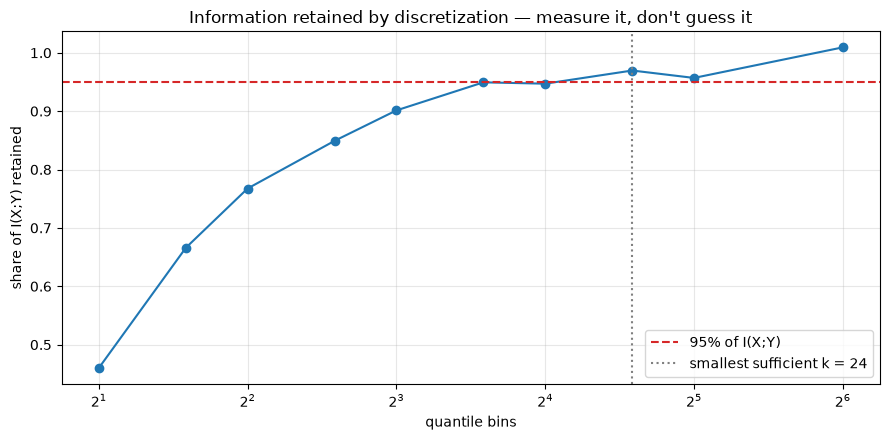

smallest k retaining ≥95%: 24 bins


In [20]:
# --- Solution ---
ks = [2, 3, 4, 6, 8, 12, 16, 24, 32, 64]
retained = []
for k in ks:
    z = np.digitize(y_d, np.quantile(y_d, np.linspace(0, 1, k + 1)[1:-1]))
    retained.append((mutual_info_classif(x_d[:, None], z, random_state=0)[0] / LN2) / mi_xy)
fig, ax = plt.subplots()
ax.plot(ks, retained, "o-")
ax.axhline(0.95, color="tab:red", ls="--", label="95% of I(X;Y)")
k95 = next(k for k, r in zip(ks, retained) if r >= 0.95)
ax.axvline(k95, color="gray", ls=":", label=f"smallest sufficient k = {k95}")
ax.set_xscale("log", base=2); ax.set_xlabel("quantile bins"); ax.set_ylabel("share of I(X;Y) retained")
ax.set_title("Information retained by discretization — measure it, don't guess it")
ax.legend(); plt.tight_layout(); plt.show()
print(f"smallest k retaining ≥95%: {k95} bins")